# 02 Projection: are disagreements at class borders, and do they follow drift?

UMAP of the float CNN's global-average-pool features (`aiv/features.py`, fixed subset of test images) for clean and corrupted inputs, coloured by CNN/SNN outcome. The SNN enters only through its predictions.

**Caveats (Lecture 03):** UMAP cluster sizes and gaps are not meaningful, so the border and drift questions are answered in the original feature space (kNN label purity, cosine drift), not from the picture. Parameters are printed. Tests H5.

In [1]:
%matplotlib inline
import os
import sys
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aiv.load import CLASSES, OUTCOMES, data_source, paired, pick
from aiv.stats import wilson
from lab.config import CORRUPTIONS, SEVERITIES

CNN, SNN = pick()
W = paired(CNN, SNN)
COND = [("clean", 0)] + [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"CNN = {CNN} | SNN = {SNN} | data = {data_source()} | rows = {len(W):,}")

CNN = cnn-float | SNN = snn-sim | data = regenerated CIFAR-10-C (not official) | rows = 160,000


In [3]:
from lab.config import DATA
F = np.load(DATA / "features" / "cnn-float.npz")
FI = pd.DataFrame({"image_id": F["image_id"], "corruption": F["corruption"], "severity": F["severity"]})
X = F["features"].astype(np.float32)
X = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-8)
D = FI.merge(W, on=["image_id", "corruption", "severity"], how="left", validate="one_to_one")
D["condition"] = D.corruption + " " + D.severity.astype(str)
D["cnn"] = np.array(CLASSES)[D.pred_cnn.astype(int)]
D["snn"] = np.array(CLASSES)[D.pred_snn.astype(int)]
print(len(np.unique(FI.image_id)), "images x", FI.groupby(["corruption", "severity"]).ngroups, "conditions")

2000 images x 16 conditions


In [4]:
import umap
from sklearn.decomposition import PCA
SEV_SHOWN = [0, 3, 5]
keep = D.severity.isin(SEV_SHOWN).values
P = {"n_neighbors": 30, "min_dist": 0.1, "metric": "cosine", "random_state": 0}
pca = PCA(50, random_state=0).fit(X[keep])
Z = umap.UMAP(**P).fit_transform(pca.transform(X[keep]))
U = D[keep].reset_index(drop=True).assign(x=Z[:, 0], y=Z[:, 1])
print("PCA 50 -> UMAP", P, "| points:", len(U),
      f"| PCA variance kept {pca.explained_variance_ratio_.sum():.2f}")

PCA 50 -> UMAP {'n_neighbors': 30, 'min_dist': 0.1, 'metric': 'cosine', 'random_state': 0} | points: 14000 | PCA variance kept 0.98


## Outcome map
Grey = both right; colour only where something goes wrong.

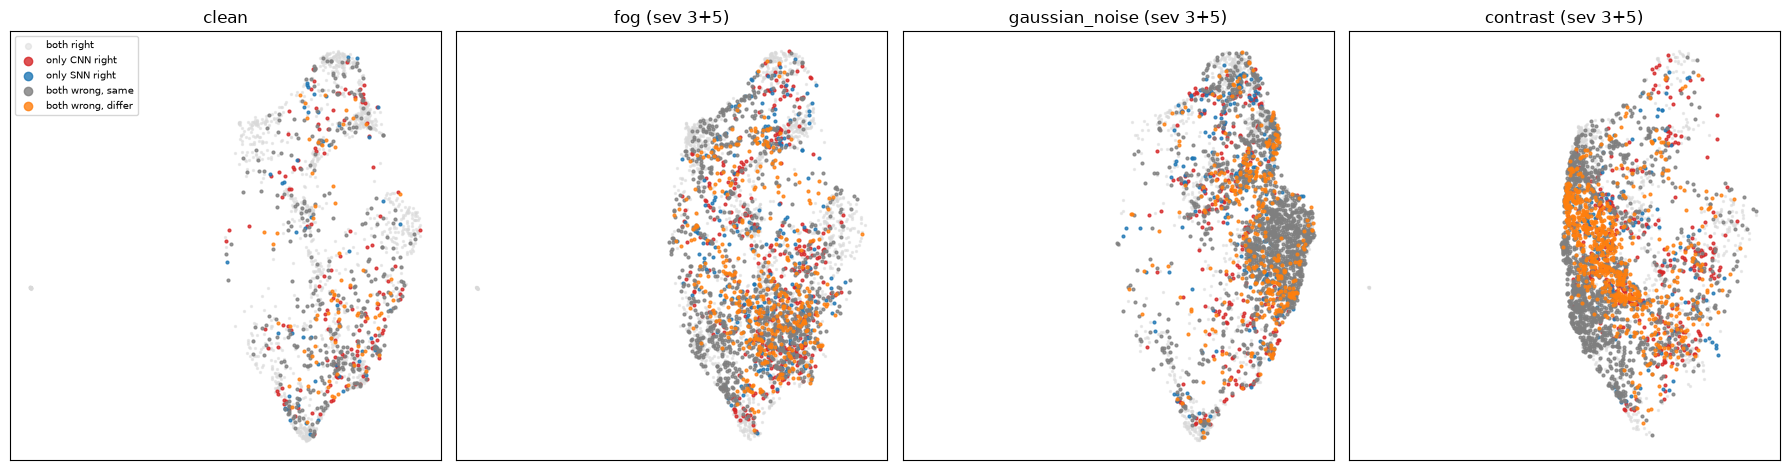

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
for ax, c in zip(axs, ["clean"] + CORRUPTIONS):
    d = U[(U.corruption == c)]
    for o in OUTCOMES:
        e = d[d.outcome == o]
        ax.scatter(e.x, e.y, s=2 if o == "both right" else 4, c=COL[o], alpha=.5 if o == "both right" else .8, label=o)
    ax.set_title(c + ("" if c == "clean" else " (sev 3+5)"))
    ax.set_xticks([])
    ax.set_yticks([])
axs[0].legend(markerscale=3, fontsize=7)
plt.tight_layout()
plt.show()

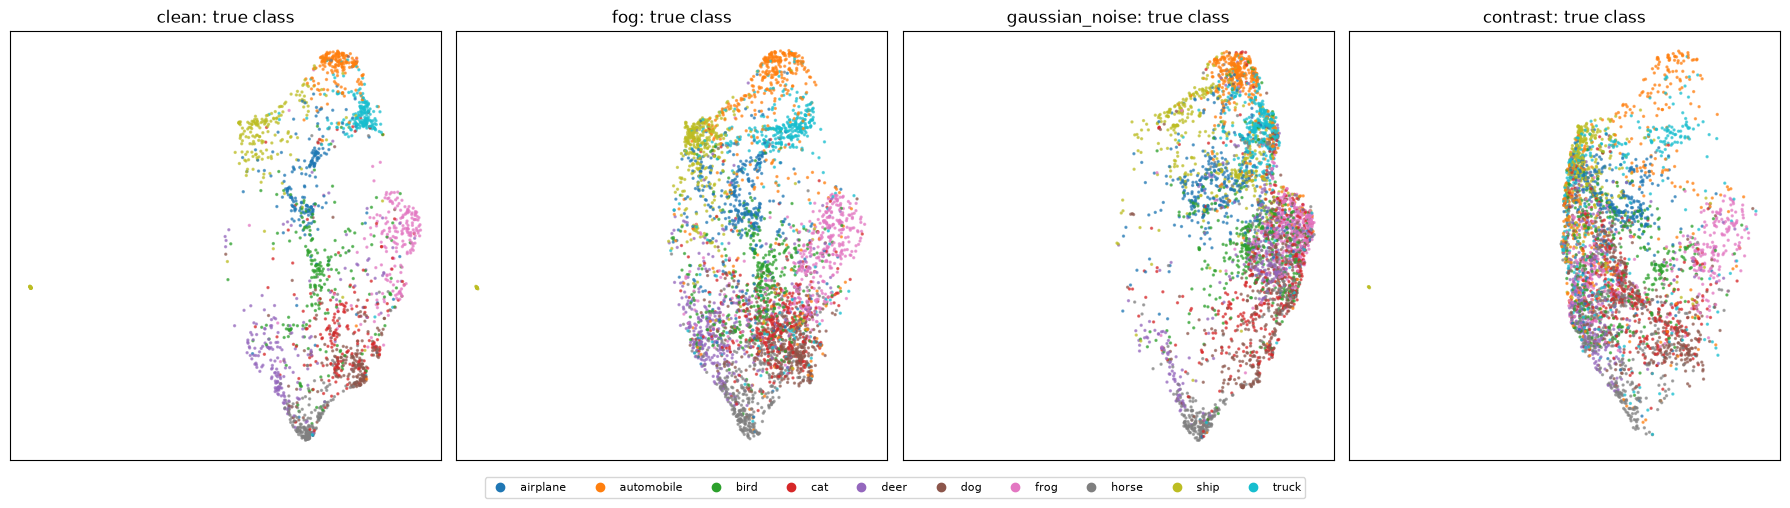

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
for ax, c in zip(axs, ["clean"] + CORRUPTIONS):
    d = U[U.corruption == c]
    ax.scatter(d.x, d.y, s=2, c=d.label, cmap="tab10", alpha=.6)
    ax.set_title(f"{c}: true class")
    ax.set_xticks([])
    ax.set_yticks([])
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=n)
                    for i, n in enumerate(CLASSES)], loc="lower center", ncol=10, fontsize=8,
           bbox_to_anchor=(.5, -.06))
plt.tight_layout()
plt.show()

Interactive version (hover for image id, labels, predictions) for exploring; use the ids in the drill-down cell.

In [7]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"  # load plotly.js from CDN instead of embedding 3 MB
fig = px.scatter(U, x="x", y="y", color="outcome", color_discrete_map=COL, facet_col="corruption",
                 facet_col_wrap=2, height=750, opacity=.6,
                 hover_data=["image_id", "condition", "true", "cnn", "snn"])
fig.update_traces(marker_size=3)
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(showticklabels=False)
fig.show()

## Border test in feature space
Label purity = share of an image's 15 nearest *clean* neighbours (cosine, original 1280-d features) with the same true class. Low purity = near a class border. Disagreement rate per purity bin, with 95 % Wilson intervals.

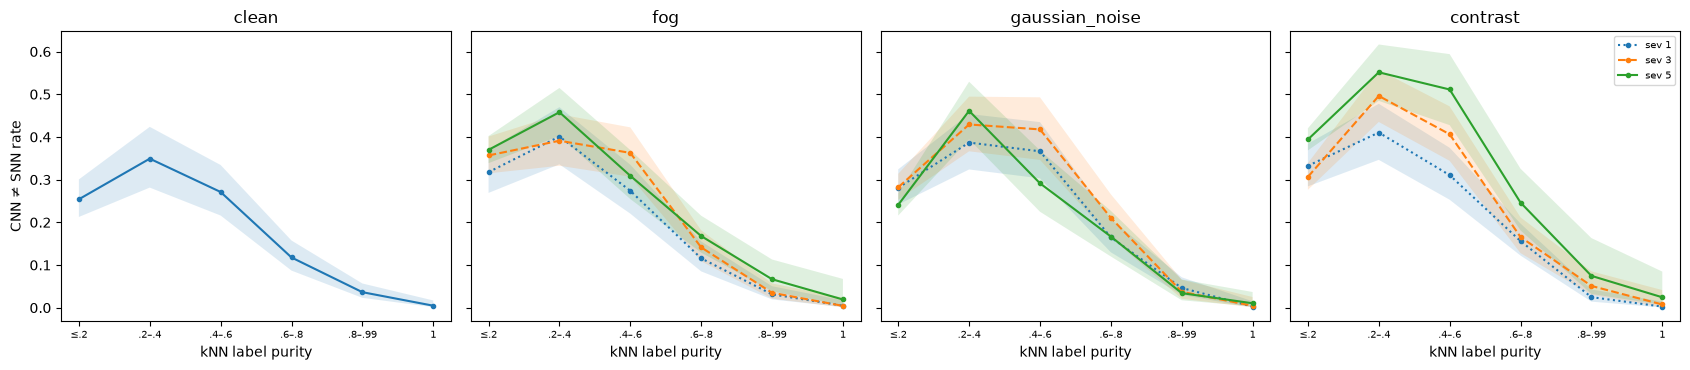

pbin    ≤.2  .2–.4  .4–.6  .6–.8  .8–.99     1
n     11132   3726   3265   4693    5292  3892


In [8]:
from sklearn.neighbors import NearestNeighbors
cl = (FI.corruption == "clean").values
nn = NearestNeighbors(n_neighbors=16, metric="cosine").fit(X[cl])
lab_clean = D.label.values[cl]
_, ix = nn.kneighbors(X)
neigh = np.where(cl[:, None], ix[:, 1:], ix[:, :15])
D["purity"] = (lab_clean[neigh] == D.label.values[:, None]).mean(1)
D["pbin"] = pd.cut(D.purity, [-.01, .2, .4, .6, .8, .99, 1.0], labels=["≤.2", ".2–.4", ".4–.6", ".6–.8", ".8–.99", "1"])
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, c in zip(axs, ["clean"] + CORRUPTIONS):
    for s, ls in ((0, "-"),) if c == "clean" else ((1, ":"), (3, "--"), (5, "-")):
        g = D[(D.corruption == c) & (D.severity == s)].groupby("pbin", observed=False)
        k, n = g.agree.apply(lambda a: (~a).sum()), g.size()
        lo, hi = wilson(k, n)
        xs = np.arange(len(n))
        ax.plot(xs, k / n, ls, marker="o", ms=3, label=f"sev {s}")
        ax.fill_between(xs, lo, hi, alpha=.15)
    ax.set_xticks(range(6))
    ax.set_xticklabels(n.index, fontsize=7)
    ax.set_title(c)
    ax.set_xlabel("kNN label purity")
axs[0].set_ylabel("CNN ≠ SNN rate")
axs[-1].legend(fontsize=7)
plt.tight_layout()
plt.show()
print(D.groupby("pbin", observed=False).size().rename("n").to_frame().T)

## Drift test
Cosine distance between each image's corrupted and clean feature vector. Drift grows with severity, so the test is done **within** a severity: disagreement rate per drift quintile of that severity, with 95 % Wilson intervals.

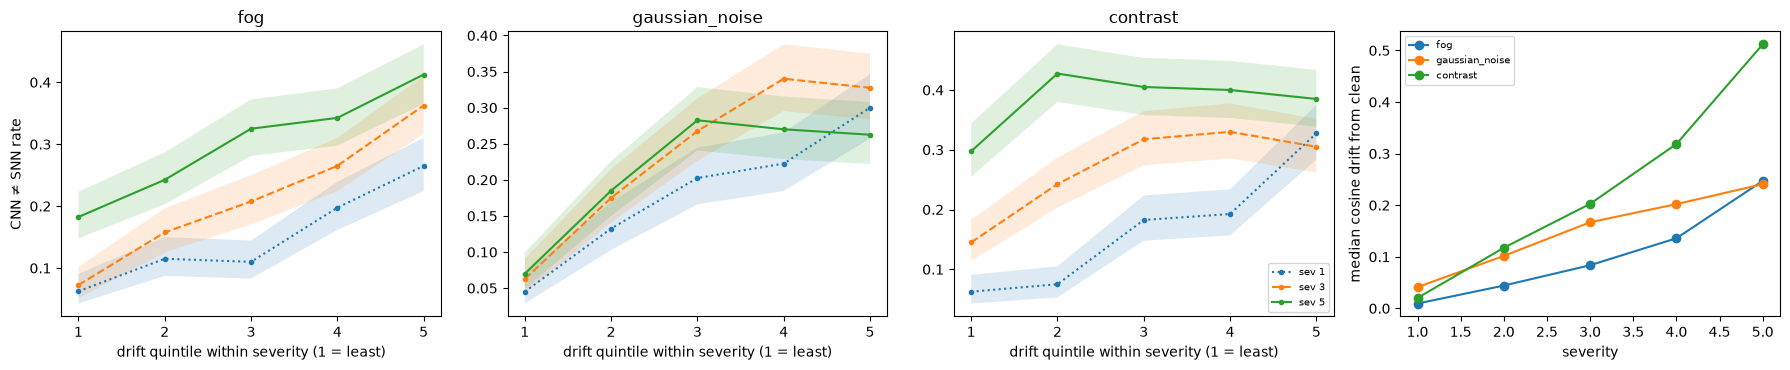

In [9]:
clean_vec = pd.Series(range(len(FI)))[cl].set_axis(FI.image_id[cl].values)
D["drift"] = 1 - (X * X[clean_vec.loc[D.image_id].values]).sum(1)
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, corr in zip(axs, CORRUPTIONS):
    for s, ls in ((1, ":"), (3, "--"), (5, "-")):
        d = D[(D.corruption == corr) & (D.severity == s)].copy()
        d["q"] = pd.qcut(d.drift, 5, labels=False)
        g = d.groupby("q")
        k, n = g.agree.apply(lambda a: (~a).sum()), g.size()
        lo, hi = wilson(k, n)
        ax.plot(k.index + 1, k / n, ls, marker="o", ms=3, label=f"sev {s}")
        ax.fill_between(k.index + 1, lo, hi, alpha=.15)
    ax.set_title(corr)
    ax.set_xlabel("drift quintile within severity (1 = least)")
    ax.set_xticks(range(1, 6))
axs[0].set_ylabel("CNN ≠ SNN rate")
axs[2].legend(fontsize=7)
for corr in CORRUPTIONS:
    m = D[D.corruption == corr].groupby("severity").drift.median()
    axs[3].plot(m.index, m.values, marker="o", label=corr)
axs[3].set_xlabel("severity")
axs[3].set_ylabel("median cosine drift from clean")
axs[3].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Drill-down

In [10]:
from lab.data import load_clean, load_corrupted

_X = {}
def images(c, s):
    if (c, s) not in _X:
        _X[(c, s)] = load_clean()[0] if c == "clean" else load_corrupted(c, s)[0]
    return _X[(c, s)]

def thumbs(df, n=24, cols=8, title=""):
    """The actual (corrupted) images behind a selection of rows of W."""
    df = df.head(n)
    if df.empty:
        print("nothing selected")
        return
    rows = int(np.ceil(len(df) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 1.35, rows * 1.75), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axs.flat, df.iterrows()):
        ax.imshow(images(r.corruption, int(r.severity))[int(r.image_id)])
        ax.set_title(f"#{int(r.image_id)} {CLASSES[r.label][:5]}\n"
                     f"C:{CLASSES[int(r.pred_cnn)][:5]} S:{CLASSES[int(r.pred_snn)][:5]}", fontsize=6.5)
    fig.suptitle(title, fontsize=9)
    plt.tight_layout()
    plt.show()

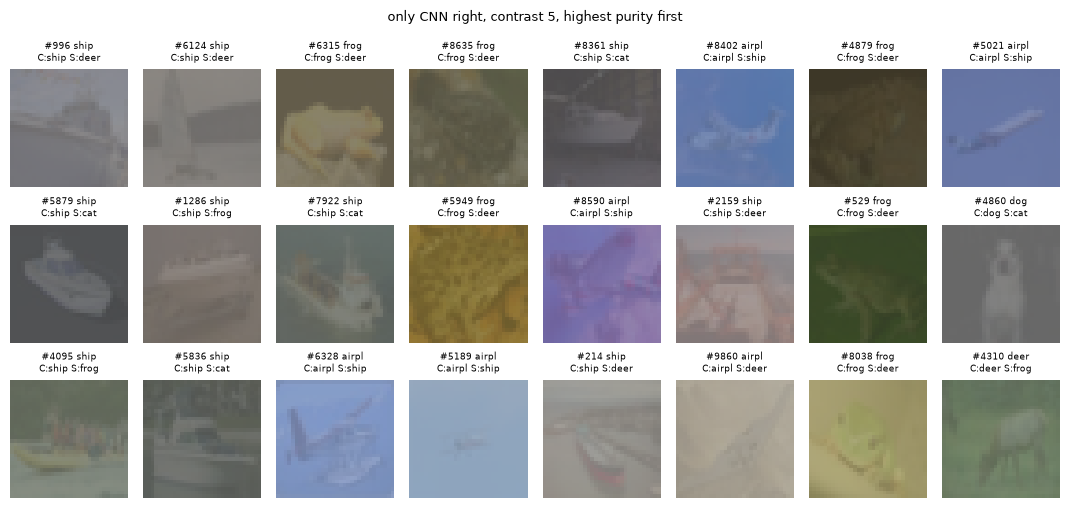

In [11]:
sel = D[(D.outcome == "only CNN right") & (D.corruption == "contrast") & (D.severity == 5)]
thumbs(sel.sort_values("purity", ascending=False), title="only CNN right, contrast 5, highest purity first")

## Findings (02 projection)

Run: `cnn-float` features for a fixed subset of 2000 test images × 16 conditions; outcomes
from `cnn-float` vs `snn-sim` on **regenerated** CIFAR-10-C. 95 % Wilson intervals.
The map is only for looking. The tests are done in the 1280-d feature space.

1. **On the map:** clean disagreements are scattered along the edges between class regions.
   Under noise and contrast, disagreements and shared errors pile up in one region (the right
   band for noise, the left band for contrast), which matches the sink classes in 01. Cluster
   sizes and gaps are not interpreted.
2. **Disagreements sit at class borders (H5, first half: supported).** Clean images whose 15
   nearest clean neighbours are mostly other classes (label purity ≤ 0.4, n = 543) disagree in
   28.4 % of cases. At purity 1 (n = 425) the rate is 0.5 %. Every corruption and severity shows
   the same curve. It peaks at purity 0.2–0.4 and is lower at ≤ 0.2, because deep inside another
   class both models are wrong *in the same way* (clean, purity ≤ 0.2: 72 % "both wrong, same").
3. **Disagreement grows with drift from the clean features within a severity, but only up to
   a point (H5, second half: supported at low/mid severity).** Most-drifted vs least-drifted
   fifth: fog 3: 0.36 [0.32, 0.41] vs 0.07 [0.05, 0.10]; noise 3: 0.33 vs 0.06; contrast 1:
   0.33 vs 0.06. At severity 5 the curve rises over the first two or three fifths and then
   flattens (noise) or dips slightly (contrast: 0.30 → 0.43 → 0.39), so very large drift adds
   no more disagreement. These images are far gone for both models.
4. **Contrast moves the CNN features most.** Median cosine drift at severity 5 is 0.51 for
   contrast and about 0.24 for fog and noise. This fits contrast producing the largest
   disagreement (37.8 % at severity 5).

Limits: CNN features only (the SNN is not projected); a 2000-image subset; drift and purity are
measured in the CNN's space, so they describe where the CNN puts an image, not the SNN.
